In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print(f'NumPy version: {np.__version__}')
print('Imports successful.')

NumPy version: 2.1.3
Imports successful.


In [ ]:
def generate_sensor_stream(samples=1000, features=3, seed=42):
    """Generates synthetic multivariate time-series baseline sensor data."""
    np.random.seed(seed)
    t = np.linspace(0, 50, samples)
    stream = np.zeros((samples, features))
    for f in range(features):
        stream[:, f] = np.sin(t * (f + 1)) + np.random.normal(0, 0.05, samples)
    return stream

clean_stream = generate_sensor_stream(samples=1000, features=3)
print(f'Clean stream shape: {clean_stream.shape}')   # Expected: (1000, 3)
print(f'Value range: [{clean_stream.min():.3f}, {clean_stream.max():.3f}]')
assert clean_stream.shape == (1000, 3), 'Shape mismatch'
print('Shape assertion passed.')

Clean stream shape: (1000, 3)
Value range: [-1.126, 1.157]
Shape assertion passed.


In [ ]:
def inject_tactical_jamming(raw_data, start_idx=400, end_idx=550, variance=2.5):
    """
    Injects high-variance Gaussian noise into a localized index window
    to simulate active tactical signal jamming.

    Parameters
    ----------
    raw_data   : np.ndarray, shape (T, F)
    start_idx  : int — first row of the jamming window (inclusive)
    end_idx    : int — last row of the jamming window (exclusive)
    variance   : float — std dev of injected Gaussian noise

    Returns
    -------
    poisoned_data : np.ndarray, shape (T, F) — copy with noise injected
    """
    poisoned_data = raw_data.copy()

    # TODO 1: Generate a Gaussian noise array of the correct shape
    # Shape must be (end_idx - start_idx, poisoned_data.shape[1])
    noise = np.random.normal(
    0,
    variance,
    size=(end_idx - start_idx,
          poisoned_data.shape[1])
)

    # TODO 2: Add the noise to the correct index window of poisoned_data
    # your code here
    poisoned_data[start_idx:end_idx, :] += noise

    return poisoned_data


# Apply jamming and run verification checks
jammed_stream = inject_tactical_jamming(clean_stream, start_idx=400, end_idx=550, variance=2.5)

assert jammed_stream.shape == clean_stream.shape, 'Output shape must match input shape'
assert not np.array_equal(jammed_stream[400:550], clean_stream[400:550]), \
    'Jamming window should differ from clean stream'
assert np.array_equal(jammed_stream[:400], clean_stream[:400]), \
    'Rows before window must be unchanged'
assert np.array_equal(jammed_stream[550:], clean_stream[550:]), \
    'Rows after window must be unchanged'

clean_mag  = np.abs(clean_stream[400:550]).mean()
jammed_mag = np.abs(jammed_stream[400:550]).mean()
print(f'Clean window mean |value|:  {clean_mag:.4f}')
print(f'Jammed window mean |value|: {jammed_mag:.4f}')
assert jammed_mag > clean_mag, 'Jammed window should have higher magnitude than clean'
print('All assertions passed.')

Clean window mean |value|:  0.6470
Jammed window mean |value|: 2.1654
All assertions passed.


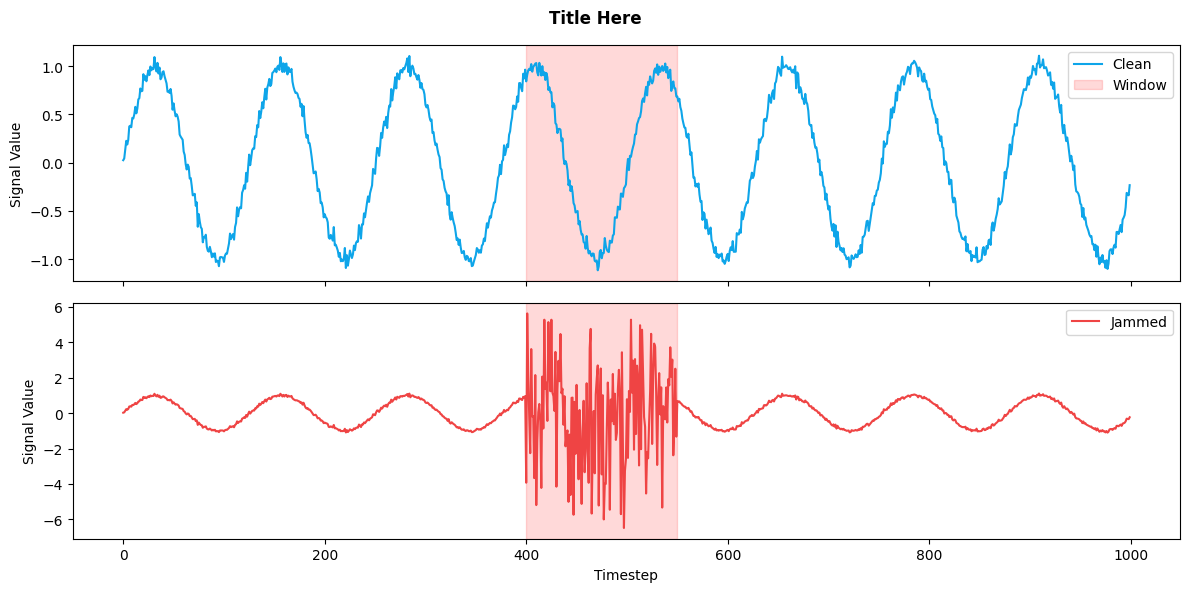

<Figure size 640x480 with 0 Axes>

Plot saved.


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
t = np.arange(1000)

axes[0].plot(clean_stream[:,0], color='#0EA5E9', label='Clean')
axes[0].axvspan(400, 550, alpha=0.15, color='red', label='Window')
axes[0].set_ylabel('Signal Value')
axes[0].legend(loc='upper right')

axes[1].plot(jammed_stream[:,0], color='#EF4444', label='Jammed')
axes[1].axvspan(400, 550, alpha=0.15, color='red')
axes[1].set_ylabel('Signal Value')
axes[1].set_xlabel('Timestep')
axes[1].legend(loc='upper right')

fig.suptitle('Title Here', fontweight='bold')
plt.tight_layout()
plt.savefig('filename.png', dpi=150, bbox_inches='tight')
plt.show()

plt.tight_layout()
plt.savefig('week02_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved.')

Q1. What happens to the signal in the jamming window compared to the clean stream? Describe both visually (what you see in the plot) and numerically (use the values printed by the assertion cell).


The clean signal stayed the same elongated motion both inside and outside the window. The jammed signal already had shorter waves, but in the window its waves spiked up and down  with a value from 6 to -6, much higher and lower than the clean smooth signal ever did at 1 and -1.


Q2. The function uses raw_data.copy() before modifying the array. What would happen if you modified raw_data directly instead? Why does this matter for the rest of the pipeline?


The function uses raw_data.copy() so that way the original clean sensor stream stays clean. The function only takes a copy of the data that can be changed. If it did not take a copy of the data then it would permanatly change the original data which is not something that is desired.


Q3. If you increased variance from 2.5 to 10.0, would the anomaly detection task become easier or harder? Explain in terms of reconstruction error and threshold calibration.

Increasing the varience from 2.5 to 10.0 would make anomoly detection easier because there would be more room for anomalies.The anomoly detection would make larger reconstruction errors in the jammed reogion which would make the anomolies stick out more.